# Notebook 10 — Root-Cause Engine and Error Propagation

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 10 of 12 — answers RQ5 and completes Objective 2

---

### What the root-cause layer is, and what it is not

The attribution is a **deterministic lookup**, confirmed in notebook 01: the physiological /
mechanical split is a pure function of (crack pattern, breeder age class), with one interpretation
text and one action text per cell of a 3 × 3 table.

| | Early lay | Peak production | Late lay |
|---|---|---|---|
| Hairline | 30 / 70 | 40 / 60 | 55 / 45 |
| Network | 50 / 50 | 60 / 40 | 75 / 25 |
| Star | 15 / 85 | 20 / 80 | 30 / 70 |

Two consequences follow, and both must be stated plainly in Chapter 5 rather than left for a
reader to work out.

**The rule base is knowledge, not a learned model.** It encodes Ross 308 specifications and the
crack-morphology literature, assembled with the hatchery manager. Its evidence base is documented
in `root_cause_rule_evidence.md`. It is not validated against hatch outcomes, and this notebook
does not pretend to validate it.

**Its accuracy is therefore bounded entirely by pattern classification.** Age class is supplied by
the user at inference, not predicted, so it is never wrong. Every root-cause error traces to a
pattern error. What this notebook measures is not whether the rules are right, but **how a
classification error propagates into a wrong attribution and a wrong recommended action** — and
crucially, whether some errors are worse than others.

### Why the propagation is not uniform

A Hairline misread as Network in a late-lay flock moves the attribution from 55 % physiological to
75 % physiological: the advice shifts emphasis but stays in the same direction. A Star misread as
Network in the same flock moves it from 30 % to 75 %: the dominant cause **flips** from mechanical
to physiological, and the manager is told to change feed when the real problem is egg handling.
Those two errors cost the same in macro F1 and are completely different operationally.

Section 3 quantifies that distinction.

---
## 0. Setup

In [ ]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"D:\Eggshell-Diagnostic-Research\Artefact"

DETECTION_THRESHOLD = 0.30    # nb 08: highest threshold with zero missed cracks on test
LOW_CONFIDENCE = 0.60         # nb 08: below this, accuracy falls under 0.5

In [2]:
import sys, json, warnings
from pathlib import Path
from datetime import datetime
_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import project_config as CFG

warnings.filterwarnings("ignore")
STAGE = "10_root_cause"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PROC = CFG.DATA_DIR / "processed"
PRED07 = CFG.RESULTS_DIR / "07_final_and_test" / "predictions"

splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
Z = np.load(PRED07 / "test_selected.npz")
idx, y4, y2, P = Z["idx"], Z["y4"], Z["y2"], Z["prob"]
p_cracked = 1.0 - P[:, 0]
pat_prob = P[:, 1:] / np.clip(P[:, 1:].sum(1, keepdims=True), 1e-9, None)

# decision rule used by the dashboard: threshold on detection, then argmax over patterns
pred4 = np.where(p_cracked >= DETECTION_THRESHOLD, pat_prob.argmax(1) + 1, 0)
conf = np.where(pred4 == 0, P[:, 0], p_cracked * pat_prob.max(1))
print(f"test n={len(y4)} | detection threshold {DETECTION_THRESHOLD}")
print(f"predicted cracked: {(pred4 > 0).sum()} | annotated cracked: {y2.sum()}")
S = {"stage": STAGE, "generated_at": datetime.now().isoformat(timespec="seconds"),
     "detection_threshold": DETECTION_THRESHOLD, "n_test": int(len(y4))}

test n=98 | detection threshold 0.3
predicted cracked: 62 | annotated cracked: 51


---
## 1. Load and verify the rule base

In [3]:
rc_path = None
for cand in [PROC / "root_cause_rules_recovered.csv", CFG.ROOT_CAUSE_RULES_CSV]:
    if Path(cand).is_file():
        rc_path = Path(cand); break
assert rc_path is not None, "no root-cause rules file found; notebook 01 writes the recovered one"
rules = pd.read_csv(rc_path)
print(f"loaded {rc_path.name}: {len(rules)} rules")

key = {}
for _, r in rules.iterrows():
    key[(str(r["crack_pattern"]).strip(), str(r["age_class"]).strip())] = {
        "phys": float(r["phys_pct"]), "mech": float(r["mech_pct"]),
        "interpretation": str(r.get("interpretation", "")),
        "actions": str(r.get("suggested_actions", "")),
    }
piv = pd.DataFrame({a: {p: key[(p, a)]["phys"] for p in CFG.PATTERNS} for a in CFG.AGE_ORDER})
print()
print(piv.to_string())
missing = [(p, a) for p in CFG.PATTERNS for a in CFG.AGE_ORDER if (p, a) not in key]
print(f"\nrule coverage: {9 - len(missing)}/9 cells" + (f"  MISSING {missing}" if missing else ""))
S["rule_coverage"] = f"{9 - len(missing)}/9"
assert not missing, f"incomplete rule base: {missing}"

loaded root_cause_rules_recovered.csv: 9 rules

          Early lay  Peak production  Late lay
Hairline       30.0             40.0      55.0
Star           15.0             20.0      30.0
Network        50.0             60.0      75.0

rule coverage: 9/9 cells


---
## 2. Per-egg dashboard output

In [4]:
def diagnose(pattern_idx, age_class, confidence):
    """Exactly what the Streamlit dashboard will show for one egg."""
    if pattern_idx == 0:
        return {"status": "Intact", "pattern": None, "phys_pct": None, "mech_pct": None,
                "interpretation": "No micro-crack detected.",
                "actions": "No action required. Set for incubation.",
                "flag": "low confidence - inspect manually" if confidence < LOW_CONFIDENCE else ""}
    p = CFG.PATTERNS[pattern_idx - 1] if pattern_idx - 1 < len(CFG.PATTERNS) else None
    # CFG.LABEL4 order is Intact, Hairline, Star, Network, so map through the label name
    p = CFG.LABEL4[pattern_idx]
    k = key[(p, age_class)]
    return {"status": "Micro_cracked", "pattern": p,
            "phys_pct": k["phys"], "mech_pct": k["mech"],
            "interpretation": k["interpretation"], "actions": k["actions"],
            "flag": "low confidence - inspect manually" if confidence < LOW_CONFIDENCE else ""}

rows = []
for i in range(len(y4)):
    r = int(idx[i])
    agec = str(splits.loc[r, "age_class"])
    out_pred = diagnose(int(pred4[i]), agec, float(conf[i]))
    out_true = diagnose(int(y4[i]), agec, 1.0)
    rows.append({
        "egg_id": splits.loc[r, "egg_id"], "age_class": agec,
        "true_label": CFG.LABEL4[int(y4[i])], "pred_label": CFG.LABEL4[int(pred4[i])],
        "correct": bool(y4[i] == pred4[i]), "confidence": round(float(conf[i]), 3),
        "true_phys": out_true["phys_pct"], "pred_phys": out_pred["phys_pct"],
        "pred_interpretation": out_pred["interpretation"],
        "pred_actions": out_pred["actions"], "flag": out_pred["flag"],
    })
dash = pd.DataFrame(rows)
dash.to_csv(TAB_DIR / "t01_per_egg_dashboard_output.csv", index=False)
print(dash.head(10).to_string(index=False))
print(f"\n{len(dash)} per-egg records written in the dashboard's exact output format")
print(f"flagged low confidence (<{LOW_CONFIDENCE}): {int((dash['flag'] != '').sum())}")
S["n_low_confidence"] = int((dash["flag"] != "").sum())

egg_id       age_class true_label pred_label  correct  confidence  true_phys  pred_phys                                                                                                                                                                       pred_interpretation                                                                                                                                                                                                                            pred_actions                              flag
  E004       Early lay     Intact     Intact     True       0.966        NaN        NaN                                                                                                                                                                  No micro-crack detected.                                                                                                                                                                                           

---
## 3. How classification errors propagate

In [5]:
both = dash.dropna(subset=["true_phys", "pred_phys"]).copy()   # annotated AND predicted cracked
both["abs_err"] = (both["pred_phys"] - both["true_phys"]).abs()
both["true_dominant"] = np.where(both["true_phys"] >= 50, "physiological", "mechanical")
both["pred_dominant"] = np.where(both["pred_phys"] >= 50, "physiological", "mechanical")
both["dominant_flipped"] = both["true_dominant"] != both["pred_dominant"]
both["action_changed"] = both["true_phys"] != both["pred_phys"]

prop = {
    "n_both_cracked": int(len(both)),
    "pattern_correct": int(both["correct"].sum()),
    "pattern_accuracy": round(float(both["correct"].mean()), 4),
    "mean_abs_error_phys_pct": round(float(both["abs_err"].mean()), 2),
    "median_abs_error_phys_pct": round(float(both["abs_err"].median()), 2),
    "max_abs_error_phys_pct": round(float(both["abs_err"].max()), 2),
    "pct_exact_attribution": round(float((both["abs_err"] == 0).mean() * 100), 1),
    "pct_dominant_cause_flipped": round(float(both["dominant_flipped"].mean() * 100), 1),
    "n_dominant_flipped": int(both["dominant_flipped"].sum()),
}
# false alarms generate a spurious diagnosis for an intact egg
fa = dash[(dash["true_label"] == "Intact") & (dash["pred_label"] != "Intact")]
miss = dash[(dash["true_label"] != "Intact") & (dash["pred_label"] == "Intact")]
prop["n_false_alarm_diagnoses"] = int(len(fa))
prop["n_missed_cracks"] = int(len(miss))
S["propagation"] = prop
print(json.dumps(prop, indent=2))

print("\nthe eggs where the DOMINANT cause flipped -- the operationally serious errors:")
flip = both[both["dominant_flipped"]][
    ["egg_id", "age_class", "true_label", "pred_label", "true_phys", "pred_phys",
     "true_dominant", "pred_dominant", "confidence"]]
flip.to_csv(TAB_DIR / "t02_dominant_cause_flips.csv", index=False)
print(flip.to_string(index=False) if len(flip) else "   none")

{
  "n_both_cracked": 51,
  "pattern_correct": 42,
  "pattern_accuracy": 0.8235,
  "mean_abs_error_phys_pct": 4.8,
  "median_abs_error_phys_pct": 0.0,
  "max_abs_error_phys_pct": 45.0,
  "pct_exact_attribution": 82.4,
  "pct_dominant_cause_flipped": 13.7,
  "n_dominant_flipped": 7,
  "n_false_alarm_diagnoses": 11,
  "n_missed_cracks": 0
}

the eggs where the DOMINANT cause flipped -- the operationally serious errors:
egg_id       age_class true_label pred_label  true_phys  pred_phys true_dominant pred_dominant  confidence
  E267        Late lay       Star    Network       30.0       75.0    mechanical physiological       0.525
  E334       Early lay    Network       Star       50.0       15.0 physiological    mechanical       0.519
  E340       Early lay   Hairline    Network       30.0       50.0    mechanical physiological       0.557
  E353 Peak production    Network       Star       60.0       20.0 physiological    mechanical       0.642
  E395 Peak production   Hairline    Network

In [6]:
# --- which confusions are operationally expensive? ----------------------
cells = []
for tp in CFG.PATTERNS:
    for pp in CFG.PATTERNS:
        for a in CFG.AGE_ORDER:
            t, p = key[(tp, a)]["phys"], key[(pp, a)]["phys"]
            cells.append({"true_pattern": tp, "pred_pattern": pp, "age_class": a,
                          "true_phys": t, "pred_phys": p, "abs_shift": abs(p - t),
                          "flips_dominant": (t >= 50) != (p >= 50)})
cost = pd.DataFrame(cells)
sev = (cost[cost["true_pattern"] != cost["pred_pattern"]]
       .groupby(["true_pattern", "pred_pattern"])
       .agg(mean_shift=("abs_shift", "mean"), max_shift=("abs_shift", "max"),
            flips=("flips_dominant", "sum")).round(1)
       .sort_values("mean_shift", ascending=False))
sev.to_csv(TAB_DIR / "t03_confusion_severity.csv")
S["confusion_severity"] = sev.reset_index().to_dict("records")
print("severity of each possible pattern confusion, averaged over age classes:")
print(sev.to_string())
print("\n'flips' counts how many of the three age classes see the dominant cause reverse.")
print("Chapter 5 should weight the confusion matrix by this table rather than treating all")
print("pattern errors as equally costly.")

severity of each possible pattern confusion, averaged over age classes:
                           mean_shift  max_shift  flips
true_pattern pred_pattern                              
Star         Network             40.0       45.0      3
Network      Star                40.0       45.0      3
Hairline     Star                20.0       25.0      1
             Network             20.0       20.0      2
Network      Hairline            20.0       20.0      2
Star         Hairline            20.0       25.0      1

'flips' counts how many of the three age classes see the dominant cause reverse.
Chapter 5 should weight the confusion matrix by this table rather than treating all
pattern errors as equally costly.


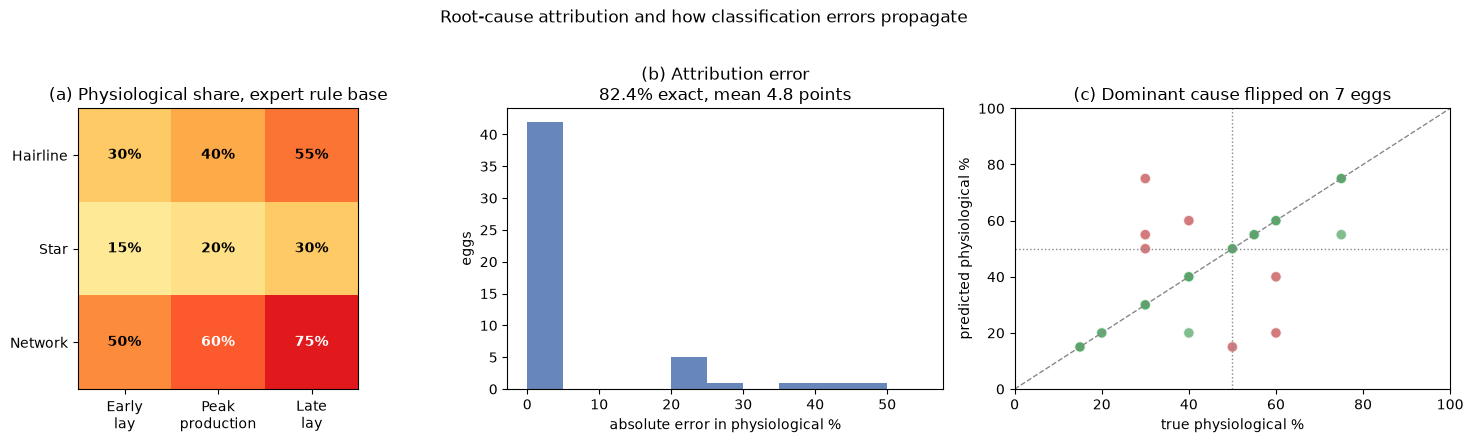

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))
ax = axes[0]
im = ax.imshow(piv.reindex(CFG.PATTERNS)[CFG.AGE_ORDER].values, cmap="YlOrRd", vmin=0, vmax=100)
for i, p in enumerate(CFG.PATTERNS):
    for j, a in enumerate(CFG.AGE_ORDER):
        v = key[(p, a)]["phys"]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontweight="bold",
                color="white" if v > 55 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels([a.replace(" ", "\n") for a in CFG.AGE_ORDER])
ax.set_yticks(range(3)); ax.set_yticklabels(CFG.PATTERNS); ax.grid(False)
ax.set_title("(a) Physiological share, expert rule base")

ax = axes[1]
if len(both):
    ax.hist(both["abs_err"], bins=np.arange(0, 60, 5), color="#4C72B0", alpha=0.85)
ax.set_xlabel("absolute error in physiological %"); ax.set_ylabel("eggs")
ax.set_title(f"(b) Attribution error\n{prop['pct_exact_attribution']}% exact, "
             f"mean {prop['mean_abs_error_phys_pct']} points")

ax = axes[2]
if len(both):
    ax.scatter(both["true_phys"], both["pred_phys"],
               c=np.where(both["dominant_flipped"], "#C44E52", "#55A868"),
               s=60, alpha=0.75, edgecolor="white")
ax.plot([0, 100], [0, 100], ls="--", color="#888", lw=1)
ax.axhline(50, ls=":", color="#888", lw=1); ax.axvline(50, ls=":", color="#888", lw=1)
ax.set_xlabel("true physiological %"); ax.set_ylabel("predicted physiological %")
ax.set_title(f"(c) Dominant cause flipped on {prop['n_dominant_flipped']} eggs")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
fig.suptitle("Root-cause attribution and how classification errors propagate", y=1.02, fontsize=12)
fig.tight_layout(); fig.savefig(FIG_DIR / "01_root_cause.png", bbox_inches="tight")
plt.show()

---
## 4. Worked examples for the dissertation

In [8]:
show = pd.concat([
    dash[dash["correct"] & dash["pred_label"].ne("Intact")].head(2),
    dash[~dash["correct"] & dash["pred_label"].ne("Intact")].head(2),
]).drop_duplicates("egg_id")
for _, r in show.iterrows():
    print("=" * 72)
    print(f"EGG {r['egg_id']}   age class: {r['age_class']}")
    print(f"  annotated : {r['true_label']}")
    print(f"  predicted : {r['pred_label']}  (confidence {r['confidence']})"
          + (f"   <-- {r['flag']}" if r["flag"] else ""))
    if r["pred_phys"] is not None and r["pred_phys"] == r["pred_phys"]:
        print(f"  attribution: {r['pred_phys']:.0f}% physiological / "
              f"{100 - r['pred_phys']:.0f}% mechanical"
              + (f"   (annotated would give {r['true_phys']:.0f}%)"
                 if r["true_phys"] == r["true_phys"] else ""))
    print(f"  interpretation: {str(r['pred_interpretation'])[:200]}")
    print(f"  actions       : {str(r['pred_actions'])[:200]}")
print("=" * 72)

EGG E067   age class: Early lay
  annotated : Hairline
  predicted : Hairline  (confidence 0.468)   <-- low confidence - inspect manually
  attribution: 30% physiological / 70% mechanical   (annotated would give 30%)
  interpretation: Single fine crack. Hairline cracks usually form when an egg strikes a hard surface, and early-lay shells are normally strong, so a handling or equipment impact is the most likely cause.
  actions       : Walk the egg route: nest mats, belt transitions and trolley or tray surfaces; collect at least 4 times a day; train staff to place eggs gently in trays. Confirm the diet has moved from pre-breeder to 
EGG E166   age class: Early lay
  annotated : Hairline
  predicted : Hairline  (confidence 0.935)
  attribution: 30% physiological / 70% mechanical   (annotated would give 30%)
  interpretation: Single fine crack. Hairline cracks usually form when an egg strikes a hard surface, and early-lay shells are normally strong, so a handling or equipment impact is th

In [9]:
def _safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return str(o)
(OUT / "root_cause_summary.json").write_text(json.dumps(S, indent=2, default=_safe))

p = S["propagation"]
L = ["=" * 70, "NOTEBOOK 10 DIGEST -- ROOT-CAUSE ENGINE", "=" * 70,
     f"generated: {S['generated_at']}",
     f"rule coverage: {S['rule_coverage']} | detection threshold {DETECTION_THRESHOLD}", "",
     "ERROR PROPAGATION (eggs both annotated and predicted as cracked)"]
for k in ["n_both_cracked", "pattern_accuracy", "pct_exact_attribution",
          "mean_abs_error_phys_pct", "median_abs_error_phys_pct", "max_abs_error_phys_pct",
          "pct_dominant_cause_flipped", "n_dominant_flipped",
          "n_false_alarm_diagnoses", "n_missed_cracks"]:
    L.append(f"   {k:<30s} {p[k]}")
L += ["", f"low-confidence flags (<{LOW_CONFIDENCE}): {S['n_low_confidence']} of {S['n_test']}",
      "", "MOST SEVERE CONFUSIONS (mean shift in physiological %)"]
for r in S["confusion_severity"][:4]:
    L.append(f"   {r['true_pattern']:<9s} -> {r['pred_pattern']:<9s} "
             f"shift {r['mean_shift']:>5} pts, flips dominant cause in {r['flips']}/3 age classes")
L.append("=" * 70)
digest = "\n".join(L)
(OUT / "digest.txt").write_text(digest)
print(digest)

NOTEBOOK 10 DIGEST -- ROOT-CAUSE ENGINE
generated: 2026-10-09T23:28:51
rule coverage: 9/9 | detection threshold 0.3

ERROR PROPAGATION (eggs both annotated and predicted as cracked)
   n_both_cracked                 51
   pattern_accuracy               0.8235
   pct_exact_attribution          82.4
   mean_abs_error_phys_pct        4.8
   median_abs_error_phys_pct      0.0
   max_abs_error_phys_pct         45.0
   pct_dominant_cause_flipped     13.7
   n_dominant_flipped             7
   n_false_alarm_diagnoses        11
   n_missed_cracks                0

low-confidence flags (<0.6): 18 of 98

MOST SEVERE CONFUSIONS (mean shift in physiological %)
   Star      -> Network   shift  40.0 pts, flips dominant cause in 3/3 age classes
   Network   -> Star      shift  40.0 pts, flips dominant cause in 3/3 age classes
   Hairline  -> Star      shift  20.0 pts, flips dominant cause in 1/3 age classes
   Hairline  -> Network   shift  20.0 pts, flips dominant cause in 2/3 age classes
